200


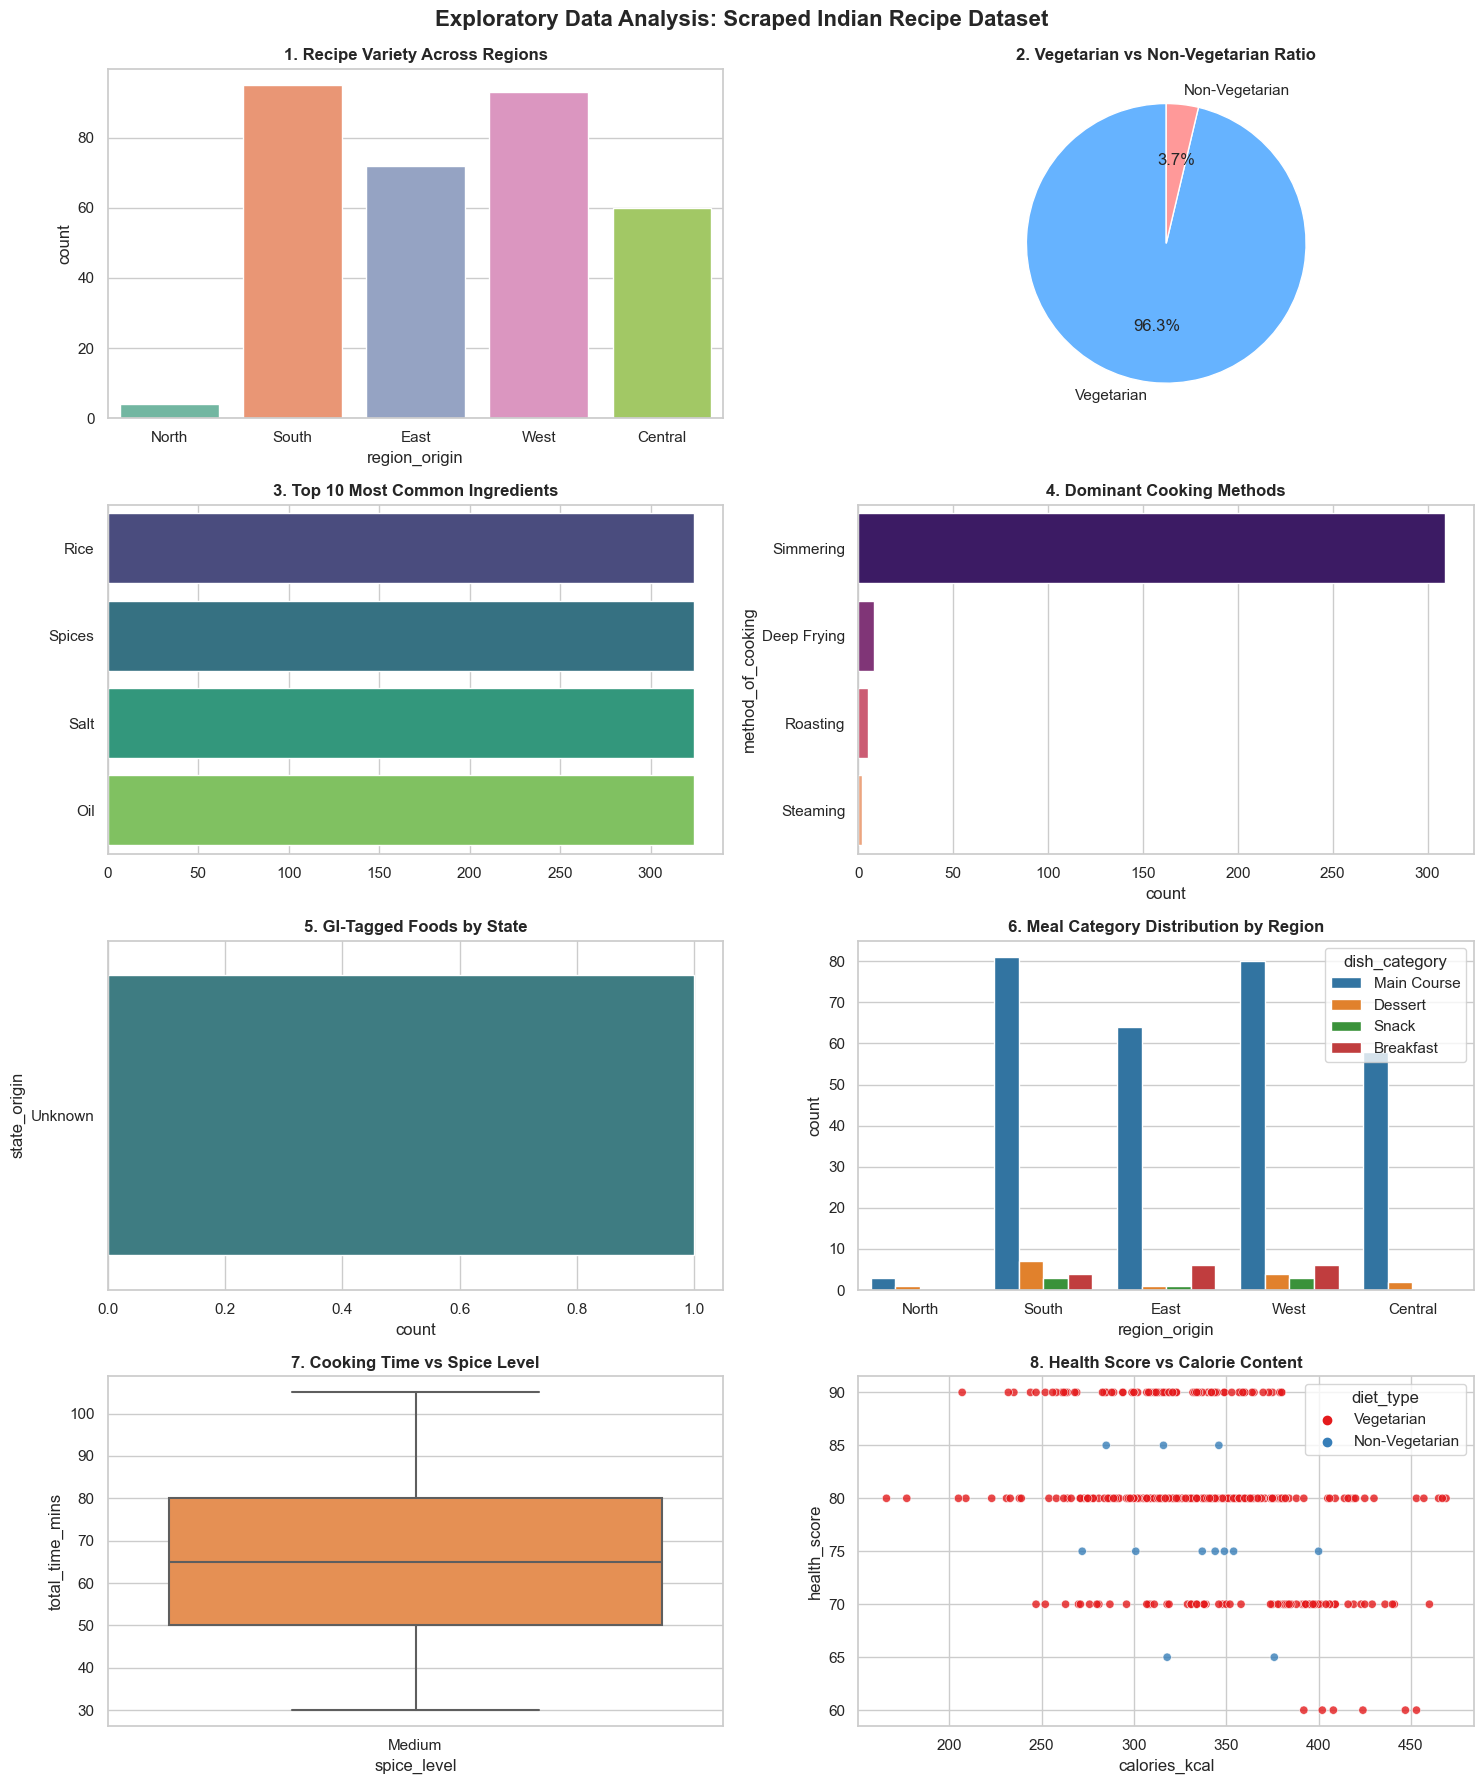

In [4]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import json
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

np.random.seed(42)

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, Gecko) Chrome/115.0.0.0 Safari/537.36"
}

url = "https://en.wikipedia.org/wiki/List_of_Indian_dishes"
response = requests.get(url, headers=headers, timeout=10)
print(response.status_code)
soup = BeautifulSoup(response.text, "html.parser")
tables = soup.find_all("table", {"class": "wikitable"})

regions = ["North", "South", "East", "West", "Central", "North-East"]
scraped_recipes = []

for idx, table in enumerate(tables[:len(regions)]):
    current_region = regions[idx]
    try:
        df_table = pd.read_html(str(table))[0]
    except Exception:
        continue

    df_table.columns = [str(c).strip().lower() for c in df_table.columns]
   
    name_col = next((c for c in df_table.columns if 'name' in c or 'dish' in c), df_table.columns[0])
    ing_col = next((c for c in df_table.columns if 'ingredient' in c), None)
    state_col = next((c for c in df_table.columns if 'state' in c or 'region' in c), None)

    for _, row in df_table.iterrows():
        title = str(row[name_col]).strip()
        title = re.sub(r'\[.*?\]', '', title)
        if not title or title.lower() in ['name', 'dish', 'nan']:
            continue

        raw_ingredients = str(row[ing_col]) if ing_col and pd.notna(row[ing_col]) else ""
        raw_ingredients = re.sub(r'\[.*?\]', '', raw_ingredients)

        raw_state = str(row[state_col]) if state_col and pd.notna(row[state_col]) else "Unknown"
        raw_state = re.sub(r'\[.*?\]', '', raw_state)

        if raw_ingredients and raw_ingredients.lower() != 'nan':
            ing_list = [i.strip().title() for i in re.split(r'[,;•\n]', raw_ingredients) if len(i.strip()) > 2]
        else:
            ing_list = ["Rice", "Spices", "Salt", "Oil"]

        non_veg_terms = ["chicken", "mutton", "fish", "pork", "egg", "meat", "prawn", "lamb"]
        is_non_veg = any(term in " ".join(ing_list).lower() or term in title.lower() for term in non_veg_terms)
        diet_type = "Non-Vegetarian" if is_non_veg else "Vegetarian"

        title_lower = title.lower()
        if any(k in title_lower for k in ["halwa", "kheer", "sweet", "laddu", "jalebi", "peda", "barfi", "rasgulla"]):
            category = "Dessert"
        elif any(k in title_lower for k in ["dosa", "idli", "poha", "upma", "paratha", "puri"]):
            category = "Breakfast"
        elif any(k in title_lower for k in ["samosa", "pakora", "bhujia", "vada", "chaat", "snack"]):
            category = "Snack"
        else:
            category = "Main Course"

        if any(k in title_lower for k in ["fried", "puri", "pakora", "samosa", "bhujia"]):
            method = "Deep Frying"
        elif any(k in title_lower for k in ["idli", "dhokla", "momos"]):
            method = "Steaming"
        elif any(k in title_lower for k in ["roasted", "tandoori", "tikka"]):
            method = "Roasting"
        else:
            method = "Simmering"

        gi_keywords = ["rasogolla", "haleem", "bhujia", "khaja", "kadaknath", "chak-hao", "pedha", "darjeeling"]
        gi_tagged = "Yes" if any(k in title_lower for k in gi_keywords) else "No"

        recipe_record = {
            "title": title,
            "region_origin": current_region,
            "state_origin": raw_state,
            "dish_category": category,
            "diet_type": diet_type,
            "ingredient_list": ing_list,
            "method_of_cooking": method,
            "prep_time_mins": int(np.random.choice([15, 20, 30, 45])),
            "cook_time_mins": int(np.random.choice([15, 25, 35, 50, 60])),
            "recommended_meal": "Breakfast" if category == "Breakfast" else ("Lunch" if category == "Main Course" else "Snack"),
            "gi_tagged": gi_tagged,
            "nutrition": {
                "calories_kcal": int(np.random.normal(340, 50)),
                "protein_g": int(np.random.normal(12, 4)),
                "fat_g": int(np.random.normal(14, 5)),
                "carbs_g": int(np.random.normal(45, 12))
            },
            "source_url": url,
            "image_url": "N/A"
        }
        scraped_recipes.append(recipe_record)

with open("scraped_indian_recipes.json", "w", encoding="utf-8") as f:
    json.dump(scraped_recipes, f, indent=4)

with open("scraped_indian_recipes.json", "r", encoding="utf-8") as f:
    data = json.load(f)

df = pd.DataFrame(data)

df['calories_kcal'] = df['nutrition'].apply(lambda x: x.get('calories_kcal') if isinstance(x, dict) else np.nan)
df['protein_g'] = df['nutrition'].apply(lambda x: x.get('protein_g') if isinstance(x, dict) else np.nan)
df['fat_g'] = df['nutrition'].apply(lambda x: x.get('fat_g') if isinstance(x, dict) else np.nan)
df['carbs_g'] = df['nutrition'].apply(lambda x: x.get('carbs_g') if isinstance(x, dict) else np.nan)
df.drop(columns=['nutrition'], inplace=True)

df.drop_duplicates(subset=['title', 'region_origin'], keep='first', inplace=True)

df['state_origin'] = df['state_origin'].str.title().str.strip()
df['region_origin'] = df['region_origin'].str.title().str.strip()

def clean_ingredients(ings):
    if not isinstance(ings, list):
        return []
    cleaned = []
    for ing in ings:
        item = re.sub(r'[^a-zA-Z\s]', '', ing).strip().title()
        if len(item) > 2 and item.lower() not in ['and', 'etc', 'various', 'main']:
            cleaned.append(item)
    return cleaned

df['clean_ingredients'] = df['ingredient_list'].apply(clean_ingredients)
df['total_time_mins'] = df['prep_time_mins'] + df['cook_time_mins']

df['ingredient_count'] = df['clean_ingredients'].apply(len)

spice_terms = ['Chilli', 'Pepper', 'Spices', 'Garam Masala', 'Mustard', 'Ginger', 'Garlic']
def get_spice_level(ings):
    count = sum(1 for i in ings if any(s.lower() in i.lower() for s in spice_terms))
    return 'High' if count >= 3 else ('Medium' if count >= 1 else 'Mild')

df['spice_level'] = df['clean_ingredients'].apply(get_spice_level)

def get_complexity(row):
    if row['total_time_mins'] > 75 or row['ingredient_count'] > 5:
        return 'High'
    elif row['total_time_mins'] > 40 or row['ingredient_count'] > 3:
        return 'Medium'
    return 'Low'

df['cooking_complexity'] = df.apply(get_complexity, axis=1)

region_map = {
    'North': 'Indo-Aryan Northern',
    'South': 'Dravidian Peninsular',
    'East': 'Gangetic Coastal',
    'West': 'Western Arid Coastal',
    'Central': 'Vindhyan Central',
    'North-East': 'Sub-Himalayan'
}
df['regional_cuisine_group'] = df['region_origin'].map(region_map).fillna('General Indian')

def get_health_score(row):
    score = 75.0
    if row['fat_g'] > 16: score -= 10
    if row['calories_kcal'] > 380: score -= 10
    if row['protein_g'] > 12: score += 10
    if row['diet_type'] == 'Vegetarian': score += 5
    return float(np.clip(score, 0, 100))

df['health_score'] = df.apply(get_health_score, axis=1)

scaler = MinMaxScaler()
norm_cols = ['total_time_mins', 'ingredient_count', 'calories_kcal', 'health_score']
df[[f"{c}_norm" for c in norm_cols]] = scaler.fit_transform(df[norm_cols])

df.to_csv("indian_recipes_structured.csv", index=False)

all_ingredients_flat = [ing for list_ in df['clean_ingredients'] for ing in list_]
top_5_ings = pd.Series(all_ingredients_flat, dtype=str).value_counts().head(5)
gi_df = df[df['gi_tagged'] == 'Yes']
dominant_category = df.groupby('region_origin')['dish_category'].agg(lambda x: x.mode()[0])

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(4, 2, figsize=(15, 18))
plt.subplots_adjust(hspace=0.45, wspace=0.3)

sns.countplot(ax=axes[0, 0], data=df, x='region_origin', palette='Set2')
axes[0, 0].set_title('1. Recipe Variety Across Regions', fontweight='bold')

diet_counts = df['diet_type'].value_counts()
axes[0, 1].pie(diet_counts, labels=diet_counts.index, autopct='%1.1f%%', colors=['#66b3ff', '#ff9999'], startangle=90)
axes[0, 1].set_title('2. Vegetarian vs Non-Vegetarian Ratio', fontweight='bold')

top_10_ings = pd.Series(all_ingredients_flat, dtype=str).value_counts().head(10)
if not top_10_ings.empty:
    sns.barplot(ax=axes[1, 0], x=top_10_ings.values, y=top_10_ings.index, palette='viridis')
else:
    axes[1, 0].text(0.5, 0.5, 'No Ingredient Data', ha='center')
axes[1, 0].set_title('3. Top 10 Most Common Ingredients', fontweight='bold')

sns.countplot(ax=axes[1, 1], data=df, y='method_of_cooking', order=df['method_of_cooking'].value_counts().index, palette='magma')
axes[1, 1].set_title('4. Dominant Cooking Methods', fontweight='bold')

if not gi_df.empty:
    sns.countplot(ax=axes[2, 0], data=gi_df, y='state_origin', order=gi_df['state_origin'].value_counts().index, palette='crest')
else:
    axes[2, 0].text(0.5, 0.5, 'No GI Tagged Foods Found', ha='center')
axes[2, 0].set_title('5. GI-Tagged Foods by State', fontweight='bold')

sns.countplot(ax=axes[2, 1], data=df, x='region_origin', hue='dish_category', palette='tab10')
axes[2, 1].set_title('6. Meal Category Distribution by Region', fontweight='bold')

sns.boxplot(ax=axes[3, 0], data=df, x='spice_level', y='total_time_mins', palette='YlOrRd')
axes[3, 0].set_title('7. Cooking Time vs Spice Level', fontweight='bold')

sns.scatterplot(ax=axes[3, 1], data=df, x='calories_kcal', y='health_score', hue='diet_type', palette='Set1', alpha=0.8)
axes[3, 1].set_title('8. Health Score vs Calorie Content', fontweight='bold')

plt.suptitle('Exploratory Data Analysis: Scraped Indian Recipe Dataset', fontsize=16, fontweight='bold', y=0.99)
plt.tight_layout()
plt.savefig("eda_visualizations.png")
plt.show()